# House Prices: Multiple Linear Regression with Preprocessing

Goal: predict `SalePrice` of houses from a few features using Multiple Linear Regression.
The main focus is correct preprocessing (missing values and a categorical feature)
without data leakage.

Dataset: [House Prices - Advanced Regression Techniques](https://www.kaggle.com/c/house-prices-advanced-regression-techniques) (`train.csv` only).

In [1]:
import pandas as pd
import numpy as np

## 1. Load the data

Load `train.csv` and keep only 7 columns:
`GrLivArea`, `OverallQual`, `GarageArea`, `LotFrontage`, `YearBuilt`, `Neighborhood` and the target `SalePrice`.

In [2]:
dataset=pd.read_csv("data/train.csv")
dataset=dataset[["GrLivArea", "OverallQual","GarageArea","LotFrontage" ,"YearBuilt", "Neighborhood","SalePrice"]]
dataset.head()

,GrLivArea,OverallQual,GarageArea,LotFrontage,YearBuilt,Neighborhood,SalePrice
0,1710,7,548,65.0,2003,CollgCr,208500
1,1262,6,460,80.0,1976,Veenker,181500
2,1786,7,608,68.0,2001,CollgCr,223500
3,1717,7,642,60.0,1915,Crawfor,140000
4,2198,8,836,84.0,2000,NoRidge,250000


## 2. Inspect the data

Check the number of rows, the data types and basic statistics.

Observations:
- The dataset has 1460 rows and 7 columns.
- `Neighborhood` is categorical (`object`), all other columns are numeric.
- `LotFrontage` has fewer non-null values than the other columns, so it has missing values.

In [3]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   GrLivArea     1460 non-null   int64  
 1   OverallQual   1460 non-null   int64  
 2   GarageArea    1460 non-null   int64  
 3   LotFrontage   1201 non-null   float64
 4   YearBuilt     1460 non-null   int64  
 5   Neighborhood  1460 non-null   object 
 6   SalePrice     1460 non-null   int64  
dtypes: float64(1), int64(5), object(1)
memory usage: 80.0+ KB


In [4]:
dataset.describe()

,GrLivArea,OverallQual,GarageArea,LotFrontage,YearBuilt,SalePrice
count,1460.000000,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000
mean,1515.463699,6.099315,472.980137,70.049958,1971.267808,180921.195890
std,525.480383,1.382997,213.804841,24.284752,30.202904,79442.502883
min,334.000000,1.000000,0.000000,21.000000,1872.000000,34900.000000
25%,1129.500000,5.000000,334.500000,59.000000,1954.000000,129975.000000
50%,1464.000000,6.000000,480.000000,69.000000,1973.000000,163000.000000
75%,1776.750000,7.000000,576.000000,80.000000,2000.000000,214000.000000
max,5642.000000,10.000000,1418.000000,313.000000,2010.000000,755000.000000


## 3. Missing values

Count the missing values in each column.

Observations:
- Only `LotFrontage` has missing values: 259 rows (about 17.74%).
- We do not impute them yet. The imputer must be fitted on the training set only,
  so we will do this after the train/test split to avoid data leakage.

In [5]:
print(dataset.isna().sum())

GrLivArea         0
OverallQual       0
GarageArea        0
LotFrontage     259
YearBuilt         0
Neighborhood      0
SalePrice         0
dtype: int64


In [6]:
print(dataset["LotFrontage"].isna().sum()/len(dataset["LotFrontage"])*100)

17.73972602739726


## 4. Separate features and target

`X` contains the 6 input features and `y` is the target (`SalePrice`).

In [7]:
X=dataset.iloc[:,0:-1].values
y=dataset.iloc[:,-1].values
print(X)
print()
print(y)

[[1710 7 548 65.0 2003 'CollgCr']
 [1262 6 460 80.0 1976 'Veenker']
 [1786 7 608 68.0 2001 'CollgCr']
 ...
 [2340 7 252 66.0 1941 'Crawfor']
 [1078 5 240 68.0 1950 'NAmes']
 [1256 5 276 75.0 1965 'Edwards']]

[208500 181500 223500 ... 266500 142125 147500]


## 5. Train/test split

Split the data into a training set (80%) and a test set (20%) with `random_state=42`.
The split is done before any preprocessing, so the test set stays unseen
and no information leaks from it.

Check: the shapes of the train and test sets should match the 80/20 ratio
(1168 and 292 rows).

In [8]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)
print (X_train.shape)
print(X_test.shape)

(1168, 6)
(292, 6)


## 6. Handle missing values

`LotFrontage` is the only column with missing values.
We fill them with the **median** of the training set using `SimpleImputer`.
The median is used because `LotFrontage` has outliers (max = 313, while the median is 69),
and the median is less sensitive to them than the mean.

The imputer is fitted on the training set only (`fit_transform`).
The test set is only transformed (`transform`) with the median learned from the training set,
so no information from the test set leaks into the training process.

Check: no NaN values remain in column `LotFrontage` of both sets.

In [9]:
from sklearn.impute import SimpleImputer
imputer=SimpleImputer(missing_values=np.nan,strategy="median")
X_train[:,3:4]=imputer.fit_transform(np.astype(X_train[:,3:4],float))
X_test[:,3:4]=imputer.transform(np.astype(X_test[:,3:4],float))
print(np.isnan(X_train[:, 3].astype(float)).sum())
print(np.isnan(X_test[:, 3].astype(float)).sum())

0
0


## 7. Encode the categorical feature

`Neighborhood` is a categorical column, so we convert it to numbers with `OneHotEncoder`
inside a `ColumnTransformer` (the other columns are passed through unchanged).

- `drop='first'` removes one dummy column to avoid the dummy variable trap,
  which would make the features perfectly collinear in Linear Regression.
- The encoder is fitted on the training set only. The test set is only transformed.

Check: both sets should have 29 columns (24 dummy columns + 5 numeric columns).

In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
ct=ColumnTransformer(transformers=[("encoder",OneHotEncoder(drop='first',sparse_output=False),[5])],remainder="passthrough")
X_train=ct.fit_transform(X_train)
X_test=ct.transform(X_test)
print(X_train.shape,X_test.shape)
print(X_train.dtype)


(1168, 29) (292, 29)
object


## 8. Train the model

Train a Linear Regression model on the preprocessed training set (`X_train`, `y_train`).

In [11]:
from sklearn.linear_model import LinearRegression
regressor=LinearRegression()
regressor.fit(X_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


## 9. Predict on the test set

Predict the prices of the test houses and compare them with the actual prices
(left column: actual price, right column: predicted price).

In [12]:
y_pred=regressor.predict(X_test)
print(np.concatenate((y_test.reshape(len(y_test),1),y_pred.reshape(len(y_pred),1)),axis=1))

[[154500.         141411.99057204]
 [325000.         336003.68925717]
 [115000.          99216.61420601]
 [159000.         174833.83623204]
 [315500.         286270.77634077]
 [ 75500.          55119.55738866]
 [311500.         229381.81111243]
 [146000.         154106.52645545]
 [ 84500.          54391.51558269]
 [135500.         126018.7106945 ]
 [145000.         153568.0107427 ]
 [130000.         110612.82363742]
 [ 81000.         108053.44244013]
 [214000.         260190.24270485]
 [181000.         186319.30508431]
 [134500.         112637.97089269]
 [183500.         205296.66794243]
 [135000.         122320.1159248 ]
 [118400.         115218.89389491]
 [226000.         207407.44575484]
 [155000.         169062.66580512]
 [210000.         241242.49066233]
 [173500.         189054.65265234]
 [129000.         113730.50938096]
 [192000.         208124.09107524]
 [153900.         161794.3628524 ]
 [181134.         186333.99320986]
 [141000.          94232.62360098]
 [181000.         18

### Evaluation metrics

- **R²**: the share of the variance in sale prices explained by the model (closer to 1 is better).
- **MAE**: the average absolute error, in dollars.
- **RMSE**: the root of the average squared error, in dollars.
  It penalizes large errors more than MAE.

Observations:
- R² is about 0.81, so the model explains about 81% of the variance of house prices on unseen data.
- MAE is about 23,074, so on average a prediction is off by about $23,000
  (the mean sale price is about $181,000, so roughly 13%).
- RMSE (about 37,675) is much larger than MAE, which means some predictions have large errors.
  For example, a house sold for 311,500 was predicted at about 229,400.

In [13]:
from sklearn.metrics import r2_score , mean_absolute_error,root_mean_squared_error
r2=r2_score(y_test,y_pred)
mae=mean_absolute_error(y_test,y_pred)
rmse=root_mean_squared_error(y_test,y_pred)
print(r2)
print(mae)
print(rmse)

0.814950715077014
23073.94749897992
37674.77113090426


## 10. Predicted vs actual prices

Scatter plot of the actual prices (x-axis) against the predicted prices (y-axis) for the test set.
The dashed/diagonal line is where predicted price equals actual price:
a perfect model would put every point on it.
Points above the line are overpredicted, points below the line are underpredicted.

Observations:
- Most points are close to the diagonal line, which matches the R² of about 0.81.
- Some points are far from the line. These are the large errors that make RMSE higher than MAE.

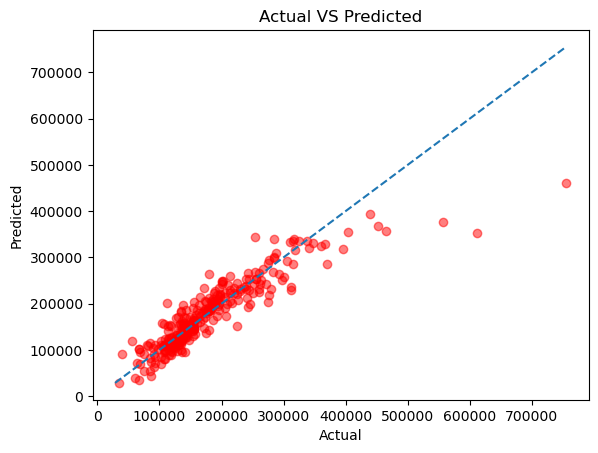

In [14]:
import matplotlib.pyplot as plt
plt.scatter(y_test,y_pred,c='red',alpha=0.5)
lo=min(y_test.min(),y_pred.min())
hi=max(y_test.max(),y_pred.max())
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.plot([lo,hi],[lo,hi],linestyle='--')
plt.title("Actual VS Predicted") 
plt.savefig("plots/predicted_vs_actual.png")
plt.show()

In [15]:
features=ct.get_feature_names_out()
dummy_names = features[:24]
numeric_names = ["GrLivArea", "OverallQual", "GarageArea", "LotFrontage", "YearBuilt"]
names = list(dummy_names) + numeric_names
print(len(names), len(regressor.coef_))

29 29


## 11. Model coefficients

The table below shows each feature with its coefficient from the Linear Regression model.
A coefficient is the change in the predicted price (in dollars) for a one-unit increase
in that feature, when all other features stay the same.

Interpretation:
- **`GrLivArea`**: one more square foot of living area is associated with a predicted price
  about $49.5 higher, when all other features are the same.
- **`YearBuilt`**: a house built one year later is predicted to cost about $364 more,
  when all other features are the same.
- **`BrDale`**: a house in this neighborhood is predicted to cost about $27,000 less
  than a similar house in the baseline neighborhood (the one removed by `drop='first'`).

Note: the features are not scaled, so the sizes of the coefficients cannot be compared directly.
Also, coefficients show associations in this data, not causes.

In [16]:
coefficient=regressor.coef_
pd.DataFrame({
    "Features":names
    ,"Coefficient":coefficient
})

,Features,Coefficient
0,encoder__x5_Blueste,-24748.571390
1,encoder__x5_BrDale,-27021.808112
2,encoder__x5_BrkSide,16684.532625
3,encoder__x5_ClearCr,45407.368831
4,encoder__x5_CollgCr,12818.355859
5,encoder__x5_Crawfor,40356.123706
6,encoder__x5_Edwards,730.783192
7,encoder__x5_Gilbert,4335.288910
8,encoder__x5_IDOTRR,3595.552860
9,encoder__x5_MeadowV,-5040.430679
